# Experiment #5: K-Means Clustering to Group Iris Flower Species

**Dataset:** Iris (`iris.csv`) - 150 flowers, 4 physical measurements + species  
**Name:** Adithya Rajesh  |  **Class:** R3AI  |  **Roll No:** B25CTA07  |  **Date:** 10-07-2026

**Objective:** Automatically group different iris flower species based on their physical characteristics using **K-Means clustering**. We drop the species column, cluster the numerical features into 3 groups, visualise the clusters, and evaluate them against the actual species.

> **Note:** The notebook must stay in the same folder as `iris.csv`.


## 1. Load the Iris Dataset and Display the First Few Records

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
df = pd.read_csv('iris.csv')
print('Shape:', df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Drop the Species Column - Keep Only Numerical Features

The `Species` column is the actual class label. For unsupervised clustering we drop it and keep only the numerical measurements as the input features `X`.


In [3]:
X = df.drop(columns=['Species', 'Id'])
print('Clustering features:', list(X.columns))
print('Feature matrix shape:', X.shape)
X.head()

Clustering features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Feature matrix shape: (150, 4)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 3. Apply K-Means Clustering with n = 3 Clusters

We group the flowers into 3 clusters (`n_clusters=3`). `random_state=16` makes the result reproducible.


In [4]:
kmeans = KMeans(n_clusters=3, random_state=16, n_init=10)
kmeans.fit(X)

clusters = kmeans.labels_
print('Cluster labels for the 150 flowers:')
print(clusters)
print('\nCluster sizes:', np.bincount(clusters))
print('Cluster centres:'); print(np.round(kmeans.cluster_centers_, 2))

Cluster labels for the 150 flowers:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 1 2 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]

Cluster sizes: [50 62 38]
Cluster centres:
[[5.01 3.42 1.46 0.24]
 [5.9  2.75 4.39 1.43]
 [6.85 3.07 5.74 2.07]]


## 4. Add the Cluster Labels to the Dataset as a New Column `cluster`

In [5]:
df['cluster'] = clusters
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,0
1,2,4.9,3.0,1.4,0.2,Iris-setosa,0
2,3,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5,5.0,3.6,1.4,0.2,Iris-setosa,0


## 5. Visualise the Clusters Using a Scatter Plot

Each cluster is drawn with a different colour. We plot `PetalLengthCm` against `PetalWidthCm` (the two most separable features).


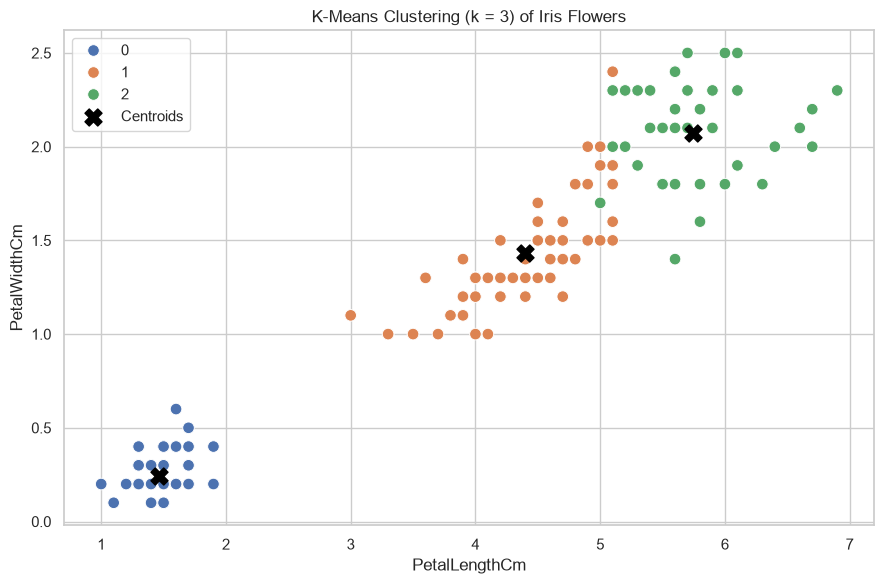

In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='PetalLengthCm', y='PetalWidthCm',
                hue='cluster', palette='deep', s=70)
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3],
            color='black', marker='X', s=150, label='Centroids')
plt.title('K-Means Clustering (k = 3) of Iris Flowers')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Compare the Cluster Labels with the Actual Species Column

K-Means cluster numbers are arbitrary, so every cluster is mapped to its majority species before accuracy is computed. We also show the contingency table between clusters and species.


In [7]:
mapping = {}
for c in range(3):
    idx = np.where(clusters == c)[0]
    mapping[c] = df.iloc[idx]['Species'].mode()[0]

print('Cluster -> species mapping:')
for c, sp in mapping.items():
    print(f'  Cluster {c}  ->  {sp}')

predicted_species = pd.Series(clusters).map(mapping).values
print('\nAccuracy (real species vs predicted):',
      round(accuracy_score(df['Species'], predicted_species), 4))
print('Adjusted Rand Index:',
      round(adjusted_rand_score(df['Species'], clusters), 4))

Cluster -> species mapping:
  Cluster 0  ->  Iris-setosa
  Cluster 1  ->  Iris-versicolor
  Cluster 2  ->  Iris-virginica

Accuracy (real species vs predicted): 0.8933
Adjusted Rand Index: 0.7302


In [8]:
comparison = pd.crosstab(df['Species'], pd.Series(clusters, name='cluster'), margins=True)
display(comparison)

cluster,0,1,2,All
Species,,,,
Iris-setosa,50,0,0,50
Iris-versicolor,0,48,2,50
Iris-virginica,0,14,36,50
All,50,62,38,150


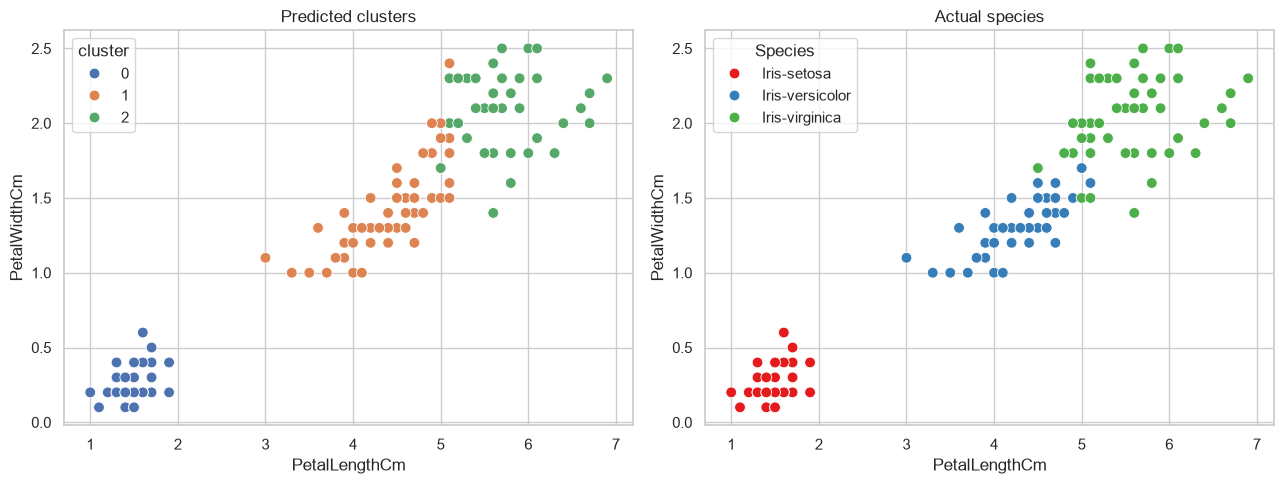

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df, x='PetalLengthCm', y='PetalWidthCm',
                hue='cluster', palette='deep', s=60, ax=axes[0])
axes[0].set_title('Predicted clusters')

sns.scatterplot(data=df, x='PetalLengthCm', y='PetalWidthCm',
                hue='Species', palette='Set1', s=60, ax=axes[1])
axes[1].set_title('Actual species')

plt.tight_layout()
plt.show()

---
## Inference & Analysis

- **Perfect cluster found:** Cluster 0 contains all 50 **setosa** flowers (they are clearly separated from the other two species).
- **Close but overlapping:** **versicolor** (48 in cluster 1) and **virginica** (36 in cluster 2) partly overlap in the measurement space, so K-Means misplaces a few specimens (14 versicolor-style rows fell into the virginica-dominated cluster and 2 the other way).
- **Mapped accuracy:** after mapping each cluster to its majority species the model matches the true labels for **89.33%** of flowers, and the Adjusted Rand Index is **0.7302** - a strong agreement given the two overlapping species.
- This confirms K-Means can auto-group flower species from physical measurements alone, with most mis-clustering occurring exactly where IRIS flowers themselves are difficult to tell apart.

---
**End of Experiment #5.**
